<a href="https://colab.research.google.com/github/Sands225/Image-and-Video-Retrieval-Archieve/blob/main/%5BTugas_3%5D_Hilbert_Transform_dan_GLCM_Image_and_Video_Retrieval_System_A.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas 3 - Video Retrieval berbasis Tekstur (GLCM) + Hilbert Transform


## 1. Mount Google Drive & Persiapan Environment


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install -q opencv-python-headless scikit-image scipy numpy pandas matplotlib

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import hilbert
from skimage.feature import graycomatrix, graycoprops

BASE_DIR = "/content/drive/MyDrive/Image Retrieval Dataset/Tugas 3"
VIDEO_DIR = os.path.join(BASE_DIR, "dataset")
OBJECT_QUERY_PATH = os.path.join(BASE_DIR, "query/query_object.png")
TEXTURE_QUERY_PATH = os.path.join(BASE_DIR, "query/query_texture.png")

VIDEO_FILES = {
    "walking": os.path.join(VIDEO_DIR, "walking.mp4"),
    "running": os.path.join(VIDEO_DIR, "running.mp4"),
    "sitting": os.path.join(VIDEO_DIR, "sitting.mp4"),
    "sky": os.path.join(VIDEO_DIR, "sky.mp4"),
    "fabric": os.path.join(VIDEO_DIR, "fabric.mp4"),
    "wood": os.path.join(VIDEO_DIR, "wood.mp4"),
}

N_KEYFRAMES = 8             # jumlah keyframe yang diambil per video
GLCM_DISTANCES = [1]        # jarak piksel untuk GLCM
GLCM_ANGLES = [0, np.pi/4, np.pi/2, 3*np.pi/4]  # 4 arah GLCM
RESIZE_DIM = (256, 256)     # ukuran standar sebelum ekstraksi fitur

## 2. Ekstraksi Keyframe dari Video


In [ ]:
def extract_keyframes(video_path, n_keyframes=N_KEYFRAMES, resize_dim=RESIZE_DIM):
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        raise FileNotFoundError(f"Tidak bisa membuka video: {video_path}")

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total_frames <= 0:
        raise ValueError(f"Video tidak memiliki frame yang terbaca: {video_path}")

    # indeks frame yang akan diambil, tersebar merata
    idxs = np.linspace(0, total_frames - 1, num=n_keyframes, dtype=int)

    frames = []
    for idx in idxs:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
        ret, frame_bgr = cap.read()
        if not ret:
            continue
        frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
        frame_rgb = cv2.resize(frame_rgb, resize_dim)
        frames.append(frame_rgb)

    cap.release()
    if len(frames) == 0:
        raise ValueError(f"Gagal mengekstrak keyframe dari: {video_path}")
    return frames

## 3. Konversi RGB -> Grayscale


In [ ]:
def rgb_to_grayscale(frame_rgb):
    """Konversi citra RGB ke grayscale (0-255, uint8) memakai bobot luminansi."""
    r = frame_rgb[:, :, 0].astype(np.float64)
    g = frame_rgb[:, :, 1].astype(np.float64)
    b = frame_rgb[:, :, 2].astype(np.float64)
    gray = 0.299 * r + 0.587 * g + 0.114 * b
    return gray.astype(np.uint8)

## 4. Fitur Tekstur GLCM (Gray Level Co-occurrence Matrix)

Untuk tiap frame grayscale dihitung GLCM pada 4 arah sudut (0°, 45°, 90°, 135°),
lalu diambil rata-rata dari 4 arah tersebut untuk setiap properti:

- **Contrast**
- **Correlation**
- **Energy**
- **Homogeneity**


In [ ]:
def compute_glcm_features(gray_img, distances=GLCM_DISTANCES, angles=GLCM_ANGLES, levels=256):
    """Menghitung fitur GLCM (Contrast, Correlation, Energy, Homogeneity),
    dirata-rata dari seluruh sudut yang digunakan."""
    glcm = graycomatrix(
        gray_img,
        distances=distances,
        angles=angles,
        levels=levels,
        symmetric=True,
        normed=True,
    )

    contrast = graycoprops(glcm, "contrast").mean()
    correlation = graycoprops(glcm, "correlation").mean()
    energy = graycoprops(glcm, "energy").mean()
    homogeneity = graycoprops(glcm, "homogeneity").mean()

    return {
        "GLCM_Contrast": contrast,
        "GLCM_Correlation": correlation,
        "GLCM_Energy": energy,
        "GLCM_Homogeneity": homogeneity,
    }

## 5. Fitur Tambahan: Transformasi Hilbert

Selain GLCM, digunakan **Transformasi Hilbert (Hilbert Transform)** untuk
menangkap karakteristik tekstur dari sisi domain sinyal. Setiap baris citra
grayscale diperlakukan sebagai sinyal 1D, kemudian dihitung *analytic signal*-nya
menggunakan `scipy.signal.hilbert`. Dari *envelope* (magnitude sinyal analitik)
tersebut diambil statistik ringkasan (mean, std, energi rata-rata) sebagai fitur
tambahan yang melengkapi fitur GLCM.


In [ ]:
def compute_hilbert_features(gray_img):
    """Menghitung fitur tekstur berbasis Transformasi Hilbert.

    Setiap baris citra dipandang sebagai sinyal 1D, ditransformasi dengan
    Hilbert Transform untuk mendapatkan analytic signal, lalu diambil
    envelope (magnitude)-nya. Statistik dari seluruh envelope dijadikan fitur.
    """
    gray_float = gray_img.astype(np.float64)

    # Transformasi Hilbert per baris (axis=1)
    analytic_signal = hilbert(gray_float, axis=1)
    envelope = np.abs(analytic_signal)

    # Fase sesaat (instantaneous phase)
    instantaneous_phase = np.unwrap(np.angle(analytic_signal), axis=1)
    phase_diff = np.diff(instantaneous_phase, axis=1)

    return {
        "Hilbert_Envelope_Mean": float(np.mean(envelope)),
        "Hilbert_Envelope_Std": float(np.std(envelope)),
        "Hilbert_Envelope_Energy": float(np.mean(envelope ** 2)),
        "Hilbert_PhaseDiff_Mean": float(np.mean(np.abs(phase_diff))),
    }

## 6. Membentuk Feature Vector per Frame & per Video

Untuk setiap keyframe: RGB -> Grayscale -> hitung fitur GLCM + fitur Hilbert
-> digabung jadi satu feature vector. Feature vector video = rata-rata
feature vector seluruh keyframe-nya.


In [ ]:
FEATURE_ORDER = [
    "GLCM_Contrast", "GLCM_Correlation", "GLCM_Energy", "GLCM_Homogeneity",
    "Hilbert_Envelope_Mean", "Hilbert_Envelope_Std",
    "Hilbert_Envelope_Energy", "Hilbert_PhaseDiff_Mean",
]

def extract_feature_vector_from_frame(frame_rgb):
    """Pipeline lengkap untuk satu frame: RGB -> Grayscale -> GLCM + Hilbert."""
    gray = rgb_to_grayscale(frame_rgb)
    feats = {}
    feats.update(compute_glcm_features(gray))
    feats.update(compute_hilbert_features(gray))
    return np.array([feats[k] for k in FEATURE_ORDER])


def extract_video_feature_vector(video_path, n_keyframes=N_KEYFRAMES):
    """Ekstraksi feature vector video = rata-rata feature vector seluruh keyframe."""
    frames = extract_keyframes(video_path, n_keyframes=n_keyframes)
    frame_vectors = [extract_feature_vector_from_frame(f) for f in frames]
    return np.mean(frame_vectors, axis=0), frames


## 7. Ekstraksi Fitur untuk Seluruh Video Dataset

Mengekstrak fitur dari walking (/content/drive/MyDrive/Image Retrieval Dataset/Tugas 3/dataset/walking.mp4) ...
Mengekstrak fitur dari running (/content/drive/MyDrive/Image Retrieval Dataset/Tugas 3/dataset/running.mp4) ...
Mengekstrak fitur dari sitting (/content/drive/MyDrive/Image Retrieval Dataset/Tugas 3/dataset/sitting.mp4) ...
Mengekstrak fitur dari sky (/content/drive/MyDrive/Image Retrieval Dataset/Tugas 3/dataset/sky.mp4) ...
Mengekstrak fitur dari fabric (/content/drive/MyDrive/Image Retrieval Dataset/Tugas 3/dataset/fabric.mp4) ...
Mengekstrak fitur dari wood (/content/drive/MyDrive/Image Retrieval Dataset/Tugas 3/dataset/wood.mp4) ...

--- Hasil Fitur GLCM ---


,GLCM_Contrast,GLCM_Correlation,GLCM_Energy,GLCM_Homogeneity
walking,409.084788,0.887618,0.023849,0.319522
running,284.382424,0.939197,0.046958,0.483953
sitting,279.369301,0.977254,0.029632,0.375145
sky,114.628688,0.982042,0.042521,0.448131
fabric,1567.445061,0.542685,0.011345,0.059483
wood,239.882126,0.741777,0.034795,0.282779



--- Hasil Fitur Hilbert ---


,Hilbert_Envelope_Mean,Hilbert_Envelope_Std,Hilbert_Envelope_Energy,Hilbert_PhaseDiff_Mean
walking,113.363580,41.976440,14614.941522,0.111499
running,128.421841,48.090838,18934.119492,0.034930
sitting,115.296953,78.580981,19475.361036,0.066642
sky,134.477178,56.335384,21445.826197,0.041430
fabric,117.149628,40.810579,16250.411710,0.278608
wood,86.994230,20.378849,7983.339848,0.115859


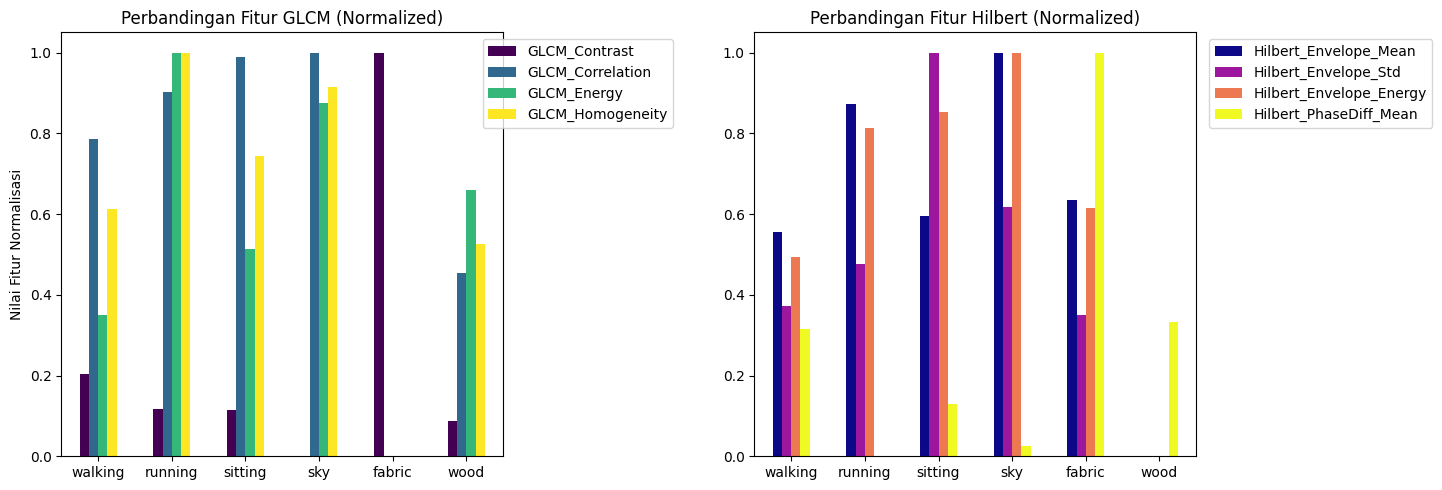

In [ ]:
video_features = {}
video_keyframes_preview = {}

for video_id, path in VIDEO_FILES.items():
    print(f"Mengekstrak fitur dari {video_id} ({path}) ...")
    vec, frames = extract_video_feature_vector(path)
    video_features[video_id] = vec
    video_keyframes_preview[video_id] = frames[0]

# Membuat DataFrame utama
df_features = pd.DataFrame(video_features, index=FEATURE_ORDER).T

# Memisahkan fitur GLCM dan Hilbert untuk perbandingan
glcm_cols = [col for col in df_features.columns if "GLCM" in col]
hilbert_cols = [col for col in df_features.columns if "Hilbert" in col]

df_glcm = df_features[glcm_cols]
df_hilbert = df_features[hilbert_cols]

print("\n--- Hasil Fitur GLCM ---")
display(df_glcm)

print("\n--- Hasil Fitur Hilbert ---")
display(df_hilbert)

# Normalisasi Min-Max agar rentang nilai (skala) fitur dapat divisualisasikan dengan seimbang
df_normalized = (df_features - df_features.min()) / (df_features.max() - df_features.min() + 1e-9)

# Visualisasi perbandingan nilai fitur per video
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

df_normalized[glcm_cols].plot(kind='bar', ax=axes[0], colormap='viridis', title='Perbandingan Fitur GLCM (Normalized)')
axes[0].set_ylabel('Nilai Fitur Normalisasi')
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(loc='upper right', bbox_to_anchor=(1.4, 1))

df_normalized[hilbert_cols].plot(kind='bar', ax=axes[1], colormap='plasma', title='Perbandingan Fitur Hilbert (Normalized)')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(loc='upper right', bbox_to_anchor=(1.55, 1))

plt.tight_layout()
plt.show()

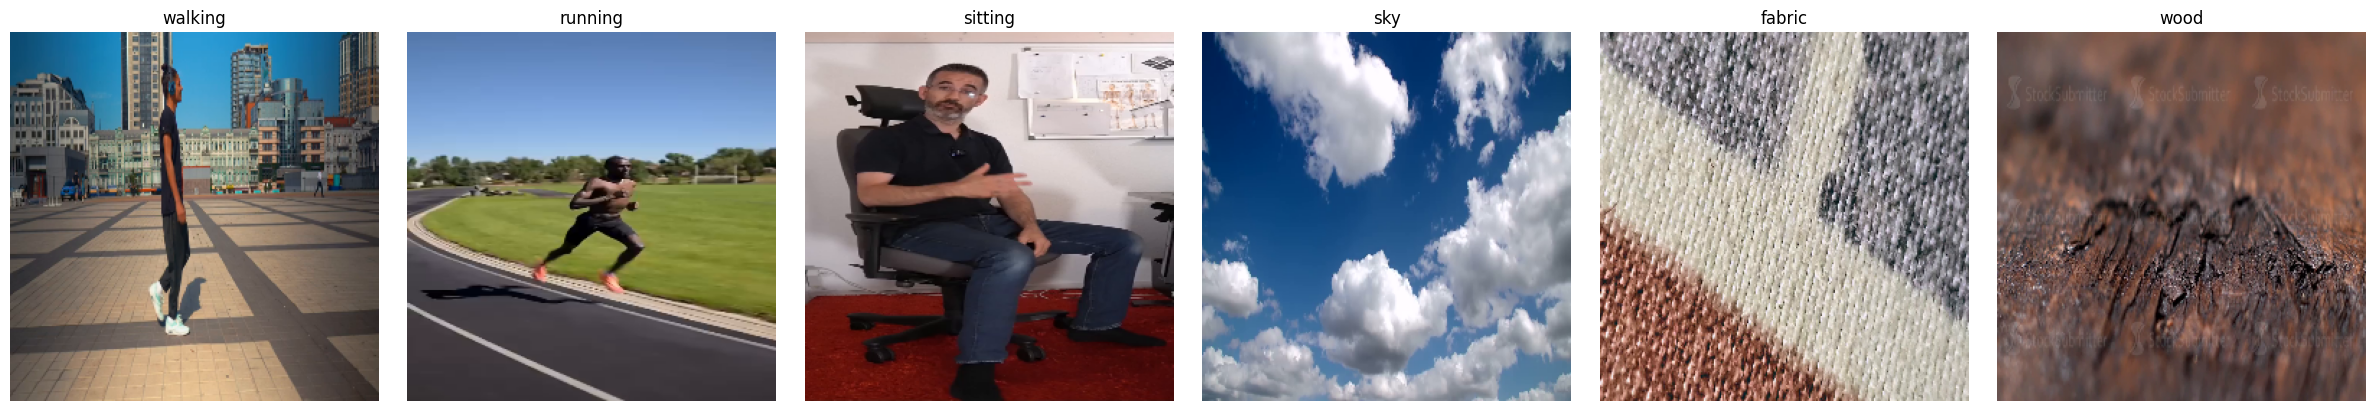

In [ ]:
# Preview 1 keyframe representatif dari tiap video
fig, axes = plt.subplots(1, len(video_keyframes_preview), figsize=(4 * len(video_keyframes_preview), 4))
for ax, (video_id, frame) in zip(axes, video_keyframes_preview.items()):
    ax.imshow(frame)
    ax.set_title(video_id)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 8. Ekstraksi Fitur untuk Query (Gambar)


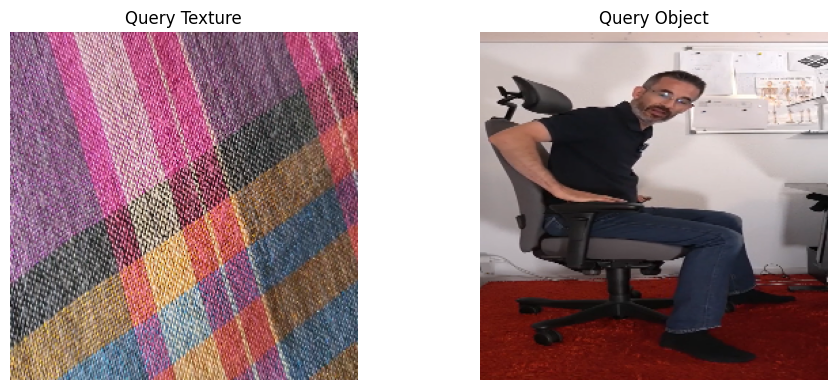

=== Vector Query Texture ===


,Query Texture
GLCM_Contrast,2678.657416
GLCM_Correlation,0.344914
GLCM_Energy,0.007573
GLCM_Homogeneity,0.029907
Hilbert_Envelope_Mean,124.526400
Hilbert_Envelope_Std,44.386556
Hilbert_Envelope_Energy,17476.990579
Hilbert_PhaseDiff_Mean,0.382767



=== Vector Query Object ===


,Query Object
GLCM_Contrast,308.225328
GLCM_Correlation,0.975425
GLCM_Energy,0.029816
GLCM_Homogeneity,0.377916
Hilbert_Envelope_Mean,118.709224
Hilbert_Envelope_Std,79.416329
Hilbert_Envelope_Energy,20398.833096
Hilbert_PhaseDiff_Mean,0.064908


In [ ]:
def extract_query_feature_vector(image_path, resize_dim=RESIZE_DIM):
    img_bgr = cv2.imread(image_path)
    if img_bgr is None:
        raise FileNotFoundError(f"Tidak bisa membaca gambar query: {image_path}")
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_rgb = cv2.resize(img_rgb, resize_dim)

    # Asumsikan extract_feature_vector_from_frame sudah didefinisikan sebelumnya
    vec = extract_feature_vector_from_frame(img_rgb)
    return vec, img_rgb

# PERBAIKAN: Gunakan extract_query_feature_vector, bukan extract_video_feature_vector
# Hasilnya langsung berupa (vector, image), bukan list frame, jadi tidak perlu [0]
query_vector_texture, query_texture_img = extract_query_feature_vector(TEXTURE_QUERY_PATH)
query_vector_object, query_object_img = extract_query_feature_vector(OBJECT_QUERY_PATH)

# Visualisasi Kedua Query Image
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(query_texture_img)
axes[0].set_title("Query Texture")
axes[0].axis("off")

axes[1].imshow(query_object_img)
axes[1].set_title("Query Object")
axes[1].axis("off")

plt.tight_layout()
plt.show()

# Menampilkan Pandas Series untuk mengecek hasil vektor salah satu query
print("=== Vector Query Texture ===")
display(pd.Series(query_vector_texture, index=FEATURE_ORDER, name="Query Texture"))

print("\n=== Vector Query Object ===")
display(pd.Series(query_vector_object, index=FEATURE_ORDER, name="Query Object"))

## 9. Similarity / Distance & Ranking

Sebelum menghitung jarak, fitur dinormalisasi (min-max terhadap seluruh video +
query) agar tiap fitur memiliki skala yang setara — GLCM dan Hilbert memiliki
rentang nilai yang jauh berbeda.

Jarak yang digunakan: **Euclidean Distance**. Semakin kecil jarak, semakin mirip
video tersebut dengan query, sehingga ranking diurutkan menaik (ascending).


In [ ]:
def euclidean_distance(v1, v2):
    return float(np.sqrt(np.sum((v1 - v2) ** 2)))

# 1. Gabungkan semua vektor (dataset + KEDUA query) untuk normalisasi min-max agar skalanya selaras
all_vectors = np.vstack(list(video_features.values()) + [query_vector_texture, query_vector_object])
f_min = all_vectors.min(axis=0)
f_max = all_vectors.max(axis=0)
f_range = np.where((f_max - f_min) == 0, 1, f_max - f_min)  # hindari pembagian nol

def normalize(vec):
    return (vec - f_min) / f_range

# Normalisasi kedua query
query_norm_texture = normalize(query_vector_texture)
query_norm_object = normalize(query_vector_object)

# 2. Cari index/posisi array untuk fitur GLCM dan Hilbert
glcm_idx = [i for i, col in enumerate(df_features.columns) if "GLCM" in col]
hilbert_idx = [i for i, col in enumerate(df_features.columns) if "Hilbert" in col]

# Potong masing-masing query menjadi bagian GLCM dan Hilbert
q_tex_glcm = query_norm_texture[glcm_idx]
q_tex_hilbert = query_norm_texture[hilbert_idx]

q_obj_glcm = query_norm_object[glcm_idx]
q_obj_hilbert = query_norm_object[hilbert_idx]

# 3. Hitung jarak untuk 4 kombinasi (Query Texture x2 metode, Query Object x2 metode)
res_tex_glcm = []
res_tex_hilbert = []
res_obj_glcm = []
res_obj_hilbert = []

for video_id, vec in video_features.items():
    vec_norm = normalize(vec)

    vec_norm_glcm = vec_norm[glcm_idx]
    vec_norm_hilbert = vec_norm[hilbert_idx]

    # Hitung Jarak Query Texture
    res_tex_glcm.append({"Video": video_id, "Distance": euclidean_distance(q_tex_glcm, vec_norm_glcm)})
    res_tex_hilbert.append({"Video": video_id, "Distance": euclidean_distance(q_tex_hilbert, vec_norm_hilbert)})

    # Hitung Jarak Query Object
    res_obj_glcm.append({"Video": video_id, "Distance": euclidean_distance(q_obj_glcm, vec_norm_glcm)})
    res_obj_hilbert.append({"Video": video_id, "Distance": euclidean_distance(q_obj_hilbert, vec_norm_hilbert)})

# 4. Buat DataFrame ranking dan urutkan
def create_ranking_df(results_list):
    df = pd.DataFrame(results_list).sort_values("Distance").reset_index(drop=True)
    df.index += 1
    df.index.name = "Rank"
    return df

df_tex_glcm = create_ranking_df(res_tex_glcm)
df_tex_hilbert = create_ranking_df(res_tex_hilbert)
df_obj_glcm = create_ranking_df(res_obj_glcm)
df_obj_hilbert = create_ranking_df(res_obj_hilbert)

## 10. Hasil Retrieval


HASIL PENCARIAN UNTUK: QUERY TEXTURE
>>> Berdasarkan Fitur GLCM:


,Video,Distance
Rank,,
1,fabric,0.545521
2,wood,1.442420
3,walking,1.444542
4,sitting,1.659068
5,sky,1.906783



>>> Berdasarkan Fitur Hilbert:


,Video,Distance
Rank,,
1,fabric,0.354647
2,walking,0.842812
3,running,1.011129
4,sky,1.065254
5,sitting,1.105107




HASIL PENCARIAN UNTUK: QUERY OBJECT
>>> Berdasarkan Fitur GLCM:


,Video,Distance
Rank,,
1,sitting,0.013929
2,walking,0.245029
3,sky,0.365756
4,wood,0.441672
5,running,0.497274



>>> Berdasarkan Fitur Hilbert:


,Video,Distance
Rank,,
1,sitting,0.100473
2,sky,0.523186
3,running,0.585360
4,walking,0.785729
5,fabric,0.949258


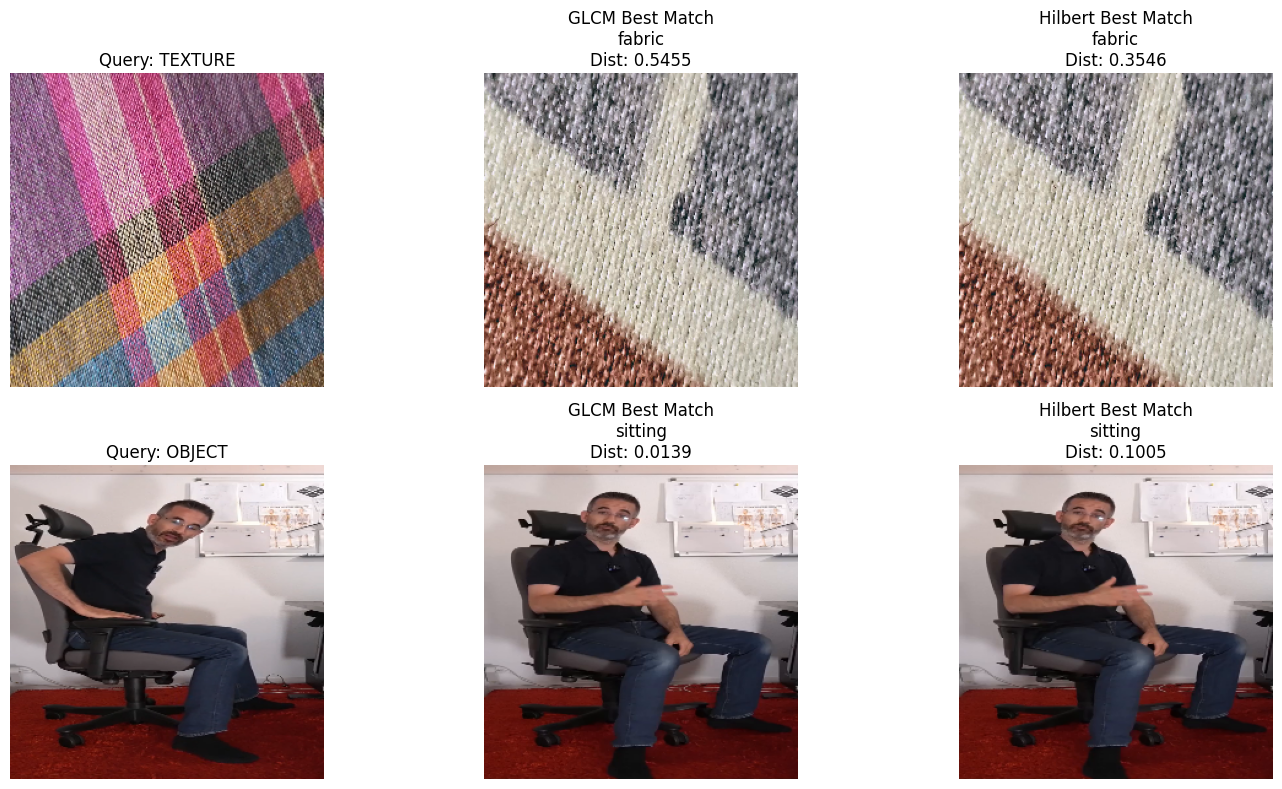

In [ ]:
# 5. Tampilkan DataFrame per Query dan Metode
print("="*50)
print("HASIL PENCARIAN UNTUK: QUERY TEXTURE")
print("="*50)
print(">>> Berdasarkan Fitur GLCM:")
display(df_tex_glcm.head())
print("\n>>> Berdasarkan Fitur Hilbert:")
display(df_tex_hilbert.head())

print("\n\n" + "="*50)
print("HASIL PENCARIAN UNTUK: QUERY OBJECT")
print("="*50)
print(">>> Berdasarkan Fitur GLCM:")
display(df_obj_glcm.head())
print("\n>>> Berdasarkan Fitur Hilbert:")
display(df_obj_hilbert.head())

# Ambil Best Match (Rank 1) beserta nilai distancenya untuk visualisasi
best_tex_g = df_tex_glcm.iloc[0]
best_tex_h = df_tex_hilbert.iloc[0]

best_obj_g = df_obj_glcm.iloc[0]
best_obj_h = df_obj_hilbert.iloc[0]

# 6. Visualisasi (Grid 2 Baris x 3 Kolom)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# --- BARIS 1: QUERY TEXTURE ---
axes[0, 0].imshow(query_texture_img)
axes[0, 0].set_title("Query: TEXTURE")
axes[0, 0].axis("off")

axes[0, 1].imshow(video_keyframes_preview[best_tex_g["Video"]])
axes[0, 1].set_title(f"GLCM Best Match\n{best_tex_g['Video']}\nDist: {best_tex_g['Distance']:.4f}")
axes[0, 1].axis("off")

axes[0, 2].imshow(video_keyframes_preview[best_tex_h["Video"]])
axes[0, 2].set_title(f"Hilbert Best Match\n{best_tex_h['Video']}\nDist: {best_tex_h['Distance']:.4f}")
axes[0, 2].axis("off")

# --- BARIS 2: QUERY OBJECT ---
axes[1, 0].imshow(query_object_img)
axes[1, 0].set_title("Query: OBJECT")
axes[1, 0].axis("off")

axes[1, 1].imshow(video_keyframes_preview[best_obj_g["Video"]])
axes[1, 1].set_title(f"GLCM Best Match\n{best_obj_g['Video']}\nDist: {best_obj_g['Distance']:.4f}")
axes[1, 1].axis("off")

axes[1, 2].imshow(video_keyframes_preview[best_obj_h["Video"]])
axes[1, 2].set_title(f"Hilbert Best Match\n{best_obj_h['Video']}\nDist: {best_obj_h['Distance']:.4f}")
axes[1, 2].axis("off")

plt.tight_layout()
plt.show()